### Iowa fatal crash data statistics and visualization

- Reads Iowa crash data for a given year (or a range of years) from 2014 to 2024 into a pandas dataframe
- Does summary statistics on some columns and plots them
- visualizes the data on a map

## Data

 The 43 fields below are the ones present in **every** year, so they are safe to use when combining years. They hold numeric codes only

**Identification**

| Field | Meaning |
|---|---|
| `STATE` | State FIPS code (always 19 = Iowa) |
| `ST_CASE` | Case number for the crash, unique within a year (190001, 190002, ...) |
| `YEAR` | Crash year (2014-2024) |

**When**

| Field | Meaning |
|---|---|
| `MONTH`, `DAY`, `DAY_WEEK` | Month, day of month, day of week (1 = Sunday) |
| `HOUR`, `MINUTE` | Time of the crash (24-hour clock; 99 = unknown) |
| `NOT_HOUR`, `NOT_MIN` | Time EMS was notified |
| `ARR_HOUR`, `ARR_MIN` | Time EMS arrived at the scene |
| `HOSP_HR`, `HOSP_MN` | Time EMS arrived at the hospital |

**Where**

| Field | Meaning |
|---|---|
| `LATITUDE`, `LONGITUD` | Crash location in decimal degrees (note the spelling `LONGITUD`) |
| `COUNTY` | County code |
| `CITY` | City code (0 = not in a city) |
| `TWAY_ID`, `TWAY_ID2` | Name or number of the trafficway; `TWAY_ID2` is the second road at an intersection and is often empty |
| `ROUTE` | Route signing (interstate, US highway, state, county, ...) |
| `NHS` | 1 if the road is on the National Highway System |
| `MILEPT` | Milepoint along the route |
| `SP_JUR` | Special jurisdiction (e.g. military or park land) |
| `RAIL` | Railroad grade crossing ID (`0000000` = none) |

**Crash circumstances**

| Field | Meaning |
|---|---|
| `HARM_EV` | First harmful event (collision with a vehicle, tree, pedestrian, rollover, ...) |
| `MAN_COLL` | Manner of collision (front-to-rear, angle, ...) |
| `TYP_INT` | Type of intersection |
| `REL_ROAD` | Where the first harmful event happened relative to the road (on roadway, shoulder, median, ...) |
| `RELJCT1`, `RELJCT2` | Whether the crash was in an interchange area, and its location relative to a junction |
| `WEATHER` | Atmospheric conditions (clear, rain, snow, fog, ...) |
| `LGT_COND` | Light condition (daylight, dark, dusk, ...) |
| `WRK_ZONE` | Work zone type (0 = not in a work zone) |
| `SCH_BUS` | 1 if a school-bus-related vehicle was involved |

**People and vehicles**

| Field | Meaning |
|---|---|
| `FATALS` | Number of people killed |
| `PERSONS` | Total people involved |
| `PERMVIT` | People in motor vehicles in transport |
| `PERNOTMVIT` | People not in motor vehicles (pedestrians, cyclists, ...) |
| `PEDS` | Pedestrians involved |
| `VE_TOTAL` | Total vehicles involved |
| `VE_FORMS` | Vehicles in transport |
| `PVH_INVL` | Parked or working vehicles involved |


In [ ]:
import pandas as pd
import folium

YEAR = 2024
DATA_FILE = f"Iowa_crashes/iowa_fars_{YEAR}.json"

df = pd.read_json(DATA_FILE)
print(f"{len(df)} crashes loaded")
# select a few columns, add more/different if you want
df[["ST_CASE", "MONTH", "DAY", "HOUR", "COUNTYNAME", "FATALS", "LATITUDE", "LONGITUD"]].head()

324 crashes loaded


,ST_CASE,MONTH,DAY,HOUR,COUNTYNAME,FATALS,LATITUDE,LONGITUD
0,190001,1,2,13,SCOTT (163),1,41.582519,-90.393364
1,190002,1,5,0,SCOTT (163),1,41.476025,-90.738117
2,190003,1,10,11,BLACK HAWK (13),1,42.538014,-92.394325
3,190004,1,7,19,MADISON (121),1,41.317692,-93.860983
4,190005,1,10,11,JONES (105),1,42.130608,-91.324214


Do some stats with the data and make plots

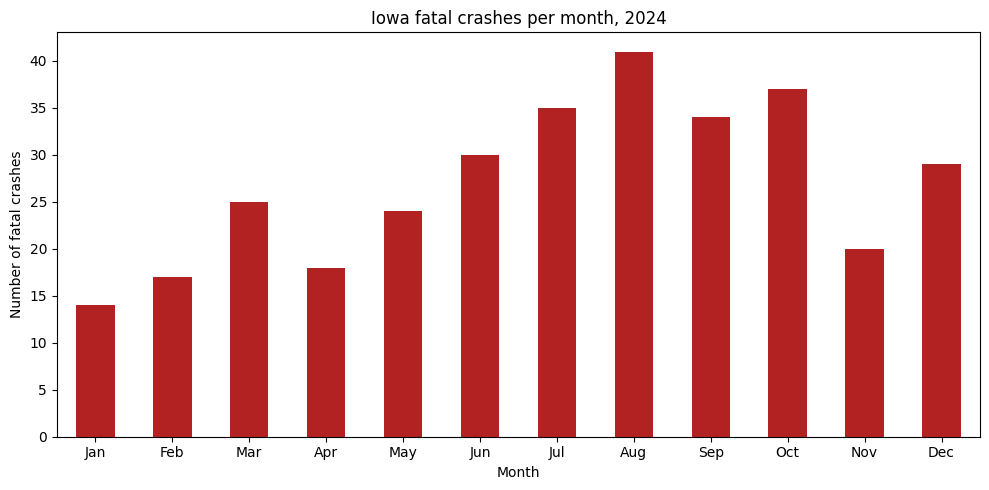

In [6]:
import matplotlib.pyplot as plt

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
per_month = df["MONTH"].value_counts().sort_index()

ax = per_month.plot(kind="bar", figsize=(10, 5), color="firebrick")
ax.set_xticklabels(month_names, rotation=0)
ax.set_xlabel("Month")
ax.set_ylabel("Number of fatal crashes")
ax.set_title(f"Iowa fatal crashes per month, {YEAR}")
plt.tight_layout()
plt.show()


### Plot data
- Make sure each data point has a valid lat/long

In [2]:
df["LATITUDE"] = pd.to_numeric(df["LATITUDE"], errors="coerce")
df["LONGITUD"] = pd.to_numeric(df["LONGITUD"], errors="coerce")

# Rough bounding box around Iowa
valid = df["LATITUDE"].between(40.3, 43.6) & df["LONGITUD"].between(-96.7, -90.1)
print(f"Dropping {(~valid).sum()} crashes without a valid Iowa location")
crashes = df[valid].copy()
len(crashes)

Dropping 0 crashes without a valid Iowa location


324

Draw on map using folium

In [10]:
iowa_center = [42.0, -93.5]
m = folium.Map(location=iowa_center, zoom_start=7, tiles="OpenStreetMap")

for row in crashes.itertuples():
    folium.CircleMarker(
        location=[row.LATITUDE, row.LONGITUD],
        radius=3,
        color="red",
        weight=1,
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
    ).add_to(m)

m